In [1]:
import numpy as np
import sys
import itertools
import matplotlib.pyplot as plt
sys.path.append("..")
from model.hopfield_network import HopfieldNetwork, SequentialHopfieldNetwork, SequentialHopfieldNetwork2

In [2]:
x1 = np.array([-1, -1,  1, -1,  1, -1, -1,  1])
x2 = np.array([-1, -1, -1, -1, -1,  1, -1, -1])
x3 = np.array([-1,  1,  1, -1, -1,  1, -1,  1])

patterns = np.array([x1, x2, x3])

hopfield = HopfieldNetwork(patterns)

print("Patterns:")
for i, pattern in enumerate(patterns):
    print(f"x{i+1}: {pattern} is stable: {hopfield.is_stable(pattern)}")
    


Patterns:
x1: [-1 -1  1 -1  1 -1 -1  1] is stable: True
x2: [-1 -1 -1 -1 -1  1 -1 -1] is stable: True
x3: [-1  1  1 -1 -1  1 -1  1] is stable: True


In [3]:
x1d = np.array([ 1, -1,  1, -1,  1, -1, -1,  1])
x2d = np.array([ 1,  1, -1, -1, -1, -1, -1, -1])
x3d = np.array([ 1,  1,  1, -1,  1,  1, -1,  1]) 
distorted_patterns = np.array([x1d, x2d, x3d])

for i, distorted_pattern in enumerate(distorted_patterns):
    print(f"\nDistorted pattern x{i+1}d: {distorted_pattern}")
    state = distorted_pattern
    final_state, history, is_stable = hopfield.recall(state, max_iterations=100)
    print(f"Final state after recall: {final_state}")
    print(f"Is stable: {is_stable}")
    

print("\n--- Ricerca degli attrattori (Automated Search) ---")
all_possible_states = np.array(list(itertools.product([-1, 1], repeat=8)))
attractors = set()
print(f"Total number of possible states: {len(all_possible_states)}")

for state in all_possible_states:
    if hopfield.is_stable(state):
        attractors.add(tuple(state))
    
print(f"Number of unique attractors found: {len(attractors)}")

for i, attractor in enumerate(attractors, start=1):
    print(f"Attractor {i}: {attractor}")
    


Distorted pattern x1d: [ 1 -1  1 -1  1 -1 -1  1]
Final state after recall: [-1 -1  1 -1  1 -1 -1  1]
Is stable: True

Distorted pattern x2d: [ 1  1 -1 -1 -1 -1 -1 -1]
Final state after recall: [ 1  1 -1  1 -1  1  1 -1]
Is stable: True

Distorted pattern x3d: [ 1  1  1 -1  1  1 -1  1]
Final state after recall: [-1  1  1 -1 -1  1 -1  1]
Is stable: True

--- Ricerca degli attrattori (Automated Search) ---
Total number of possible states: 256
Number of unique attractors found: 14
Attractor 1: (np.int64(1), np.int64(1), np.int64(-1), np.int64(1), np.int64(1), np.int64(-1), np.int64(1), np.int64(-1))
Attractor 2: (np.int64(1), np.int64(1), np.int64(-1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(-1))
Attractor 3: (np.int64(-1), np.int64(-1), np.int64(1), np.int64(-1), np.int64(1), np.int64(1), np.int64(-1), np.int64(1))
Attractor 4: (np.int64(1), np.int64(1), np.int64(-1), np.int64(1), np.int64(-1), np.int64(1), np.int64(1), np.int64(-1))
Attractor 5: (np.int64(-1), np.int


Loaded pict.dat with shape: (11264,)

Loaded pict.dat with shape: (11, 1024)
Number of patterns in pict.dat: 11


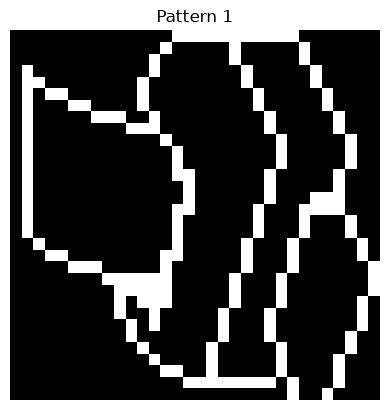

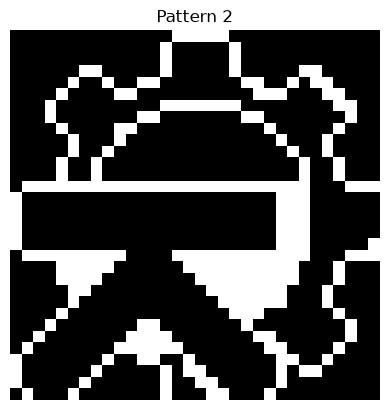

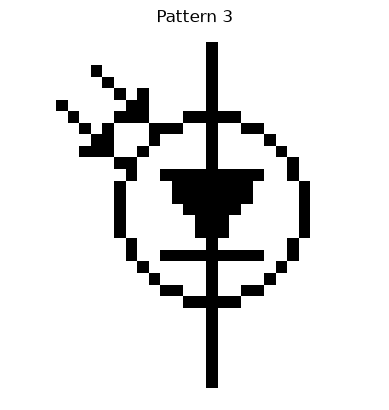

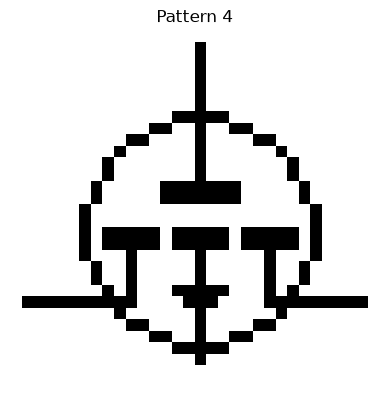

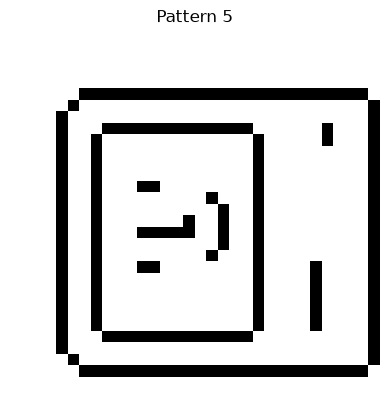

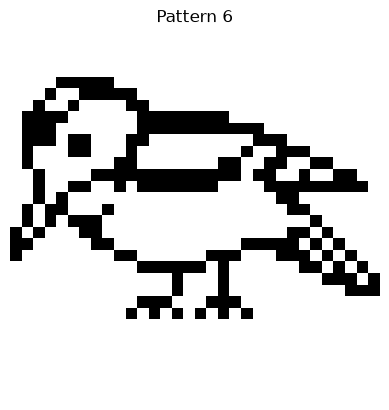

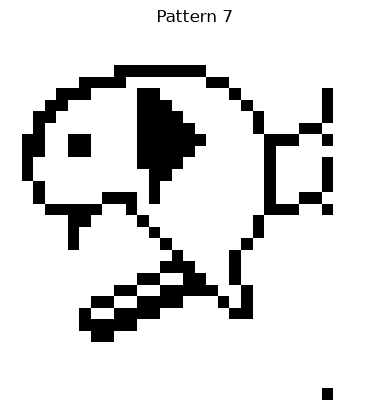

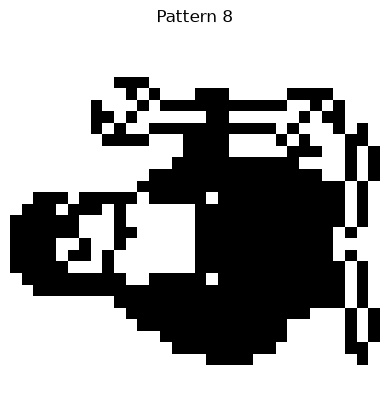

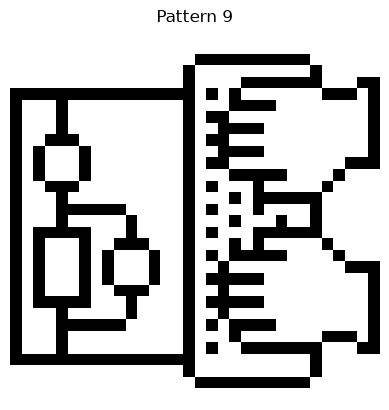

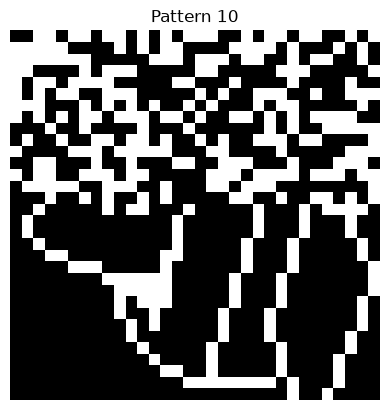

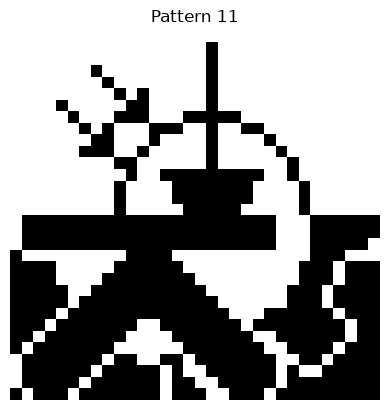

In [4]:
# load pict.dat file (format -1,1..) and plot the patterns
pict_data = np.loadtxt('../pict.dat', delimiter=',')
print(f"\nLoaded pict.dat with shape: {pict_data.shape}")
pict_data = pict_data.reshape(-1, 1024)

print(f"\nLoaded pict.dat with shape: {pict_data.shape}")

# Plot the patterns 32x32
num_patterns = pict_data.shape[0]
print(f"Number of patterns in pict.dat: {num_patterns}")
for i in range(num_patterns):
    plt.imshow(pict_data[i].reshape(32, 32), cmap='gray')
    plt.title(f'Pattern {i+1}')
    plt.axis('off')
    plt.show()

In [5]:
# ============================================================
# 3.2 Sequential Update
# ============================================================

# ------------------------------------------------------------
# 1. Select the patterns
# ------------------------------------------------------------

p1 = pict_data[0]
p2 = pict_data[1]
p3 = pict_data[2]

p10 = pict_data[9]
p11 = pict_data[10]

training_patterns = np.array([p1, p2, p3])

In [6]:
# ------------------------------------------------------------
# 2. Train the Hopfield network on p1, p2 and p3
# ------------------------------------------------------------

network = SequentialHopfieldNetwork(training_patterns)

print("Network created")
print(f"Number of neurons: {network.n_neurons}")
print(f"Weight matrix shape: {network.W.shape}")


Network created
Number of neurons: 1024
Weight matrix shape: (1024, 1024)


In [7]:
# ------------------------------------------------------------
# 3. Check that p1, p2 and p3 are stable
# ------------------------------------------------------------

print("\nChecking stability of stored patterns:")

for i, pattern in enumerate(training_patterns, start=1):
    stable = network.is_stable(pattern)
    print(f"p{i}: {'stable' if stable else 'NOT stable'}")




Checking stability of stored patterns:
p1: stable
p2: stable
p3: stable


In [8]:
# ------------------------------------------------------------
# 4. Test pattern completion with p10 and p11
# ------------------------------------------------------------

test_patterns = {
    "p10": p10,
    "p11": p11
}

print("\nTesting degraded / mixed patterns:")

for name, pattern in test_patterns.items():

    recalled, history = network.recall(
        pattern,
        iterations=1000,
        record_every=100
    )
    print(f"history length: {len(history)}")

    print(f"\n{name}")

    # Check whether the final state corresponds to one
    # of the three stored patterns
    recalled_pattern = None

    for i, stored_pattern in enumerate(training_patterns, start=1):
        if np.array_equal(recalled, stored_pattern):
            recalled_pattern = f"p{i}"
            break

    if recalled_pattern is not None:
        print(f"Converged to: {recalled_pattern}")
    else:
        print("Did not converge exactly to a stored pattern.")



Testing degraded / mixed patterns:
Iteration 100: Energy = -500400.0
Iteration 200: Energy = -589344.0
Iteration 300: Energy = -667724.0
Iteration 400: Energy = -747500.0
Iteration 500: Energy = -784640.0
Iteration 600: Energy = -841836.0
Iteration 700: Energy = -873632.0
Iteration 800: Energy = -931536.0
Iteration 900: Energy = -973712.0
Iteration 1000: Energy = -1015104.0
history length: 11

p10
Did not converge exactly to a stored pattern.
Iteration 100: Energy = -192224.0
Iteration 200: Energy = -226316.0
Iteration 300: Energy = -260368.0
Iteration 400: Energy = -287936.0
Iteration 500: Energy = -342544.0
Iteration 600: Energy = -396848.0
Iteration 700: Energy = -462188.0
Iteration 800: Energy = -520844.0
Iteration 900: Energy = -568880.0
Iteration 1000: Energy = -625484.0
history length: 11

p11
Did not converge exactly to a stored pattern.


Iteration 100: Energy = -510188.0
Iteration 200: Energy = -621456.0
Iteration 300: Energy = -690700.0
Iteration 400: Energy = -783052.0
Iteration 500: Energy = -832928.0
Iteration 600: Energy = -860976.0
Iteration 700: Energy = -901228.0
Iteration 800: Energy = -961036.0
Iteration 900: Energy = -1009056.0
Iteration 1000: Energy = -1048908.0


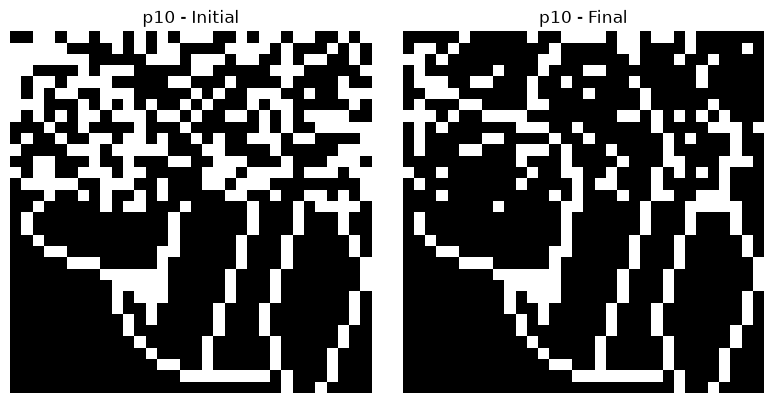

Iteration 100: Energy = -191116.0
Iteration 200: Energy = -226028.0
Iteration 300: Energy = -268096.0
Iteration 400: Energy = -329324.0
Iteration 500: Energy = -392044.0
Iteration 600: Energy = -453708.0
Iteration 700: Energy = -521356.0
Iteration 800: Energy = -590188.0
Iteration 900: Energy = -652844.0
Iteration 1000: Energy = -708844.0


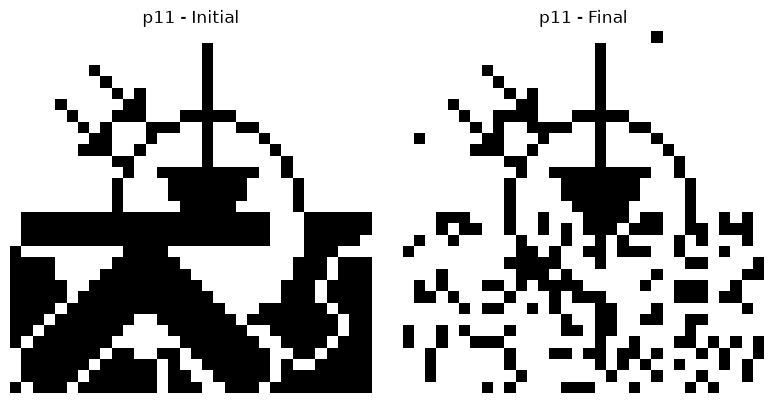

In [9]:
# ------------------------------------------------------------
# 5. Visualize the initial and final states
# ------------------------------------------------------------

for name, pattern in test_patterns.items():

    recalled, history = network.recall(
        pattern,
        iterations=1000,
        record_every=100
    )

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(pattern.reshape(32, 32), cmap="gray")
    axes[0].set_title(f"{name} - Initial")
    axes[0].axis("off")

    axes[1].imshow(recalled.reshape(32, 32), cmap="gray")
    axes[1].set_title(f"{name} - Final")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

Iteration 500: Energy = -766444.0
Iteration 1000: Energy = -973964.0
Iteration 1500: Energy = -1147104.0
Iteration 2000: Energy = -1244908.0
Iteration 2500: Energy = -1325232.0
Iteration 3000: Energy = -1410444.0
Iteration 3500: Energy = -1437740.0
Iteration 4000: Energy = -1449900.0
Iteration 4500: Energy = -1465356.0
Iteration 5000: Energy = -1465356.0
Iteration 5500: Energy = -1465356.0
Iteration 6000: Energy = -1473516.0
Iteration 6500: Energy = -1473516.0
Iteration 7000: Energy = -1473516.0
Iteration 7500: Energy = -1473516.0
Iteration 8000: Energy = -1473516.0
Iteration 8500: Energy = -1473936.0
Iteration 9000: Energy = -1473936.0
Iteration 9500: Energy = -1473936.0
Iteration 10000: Energy = -1473936.0
history length: 21


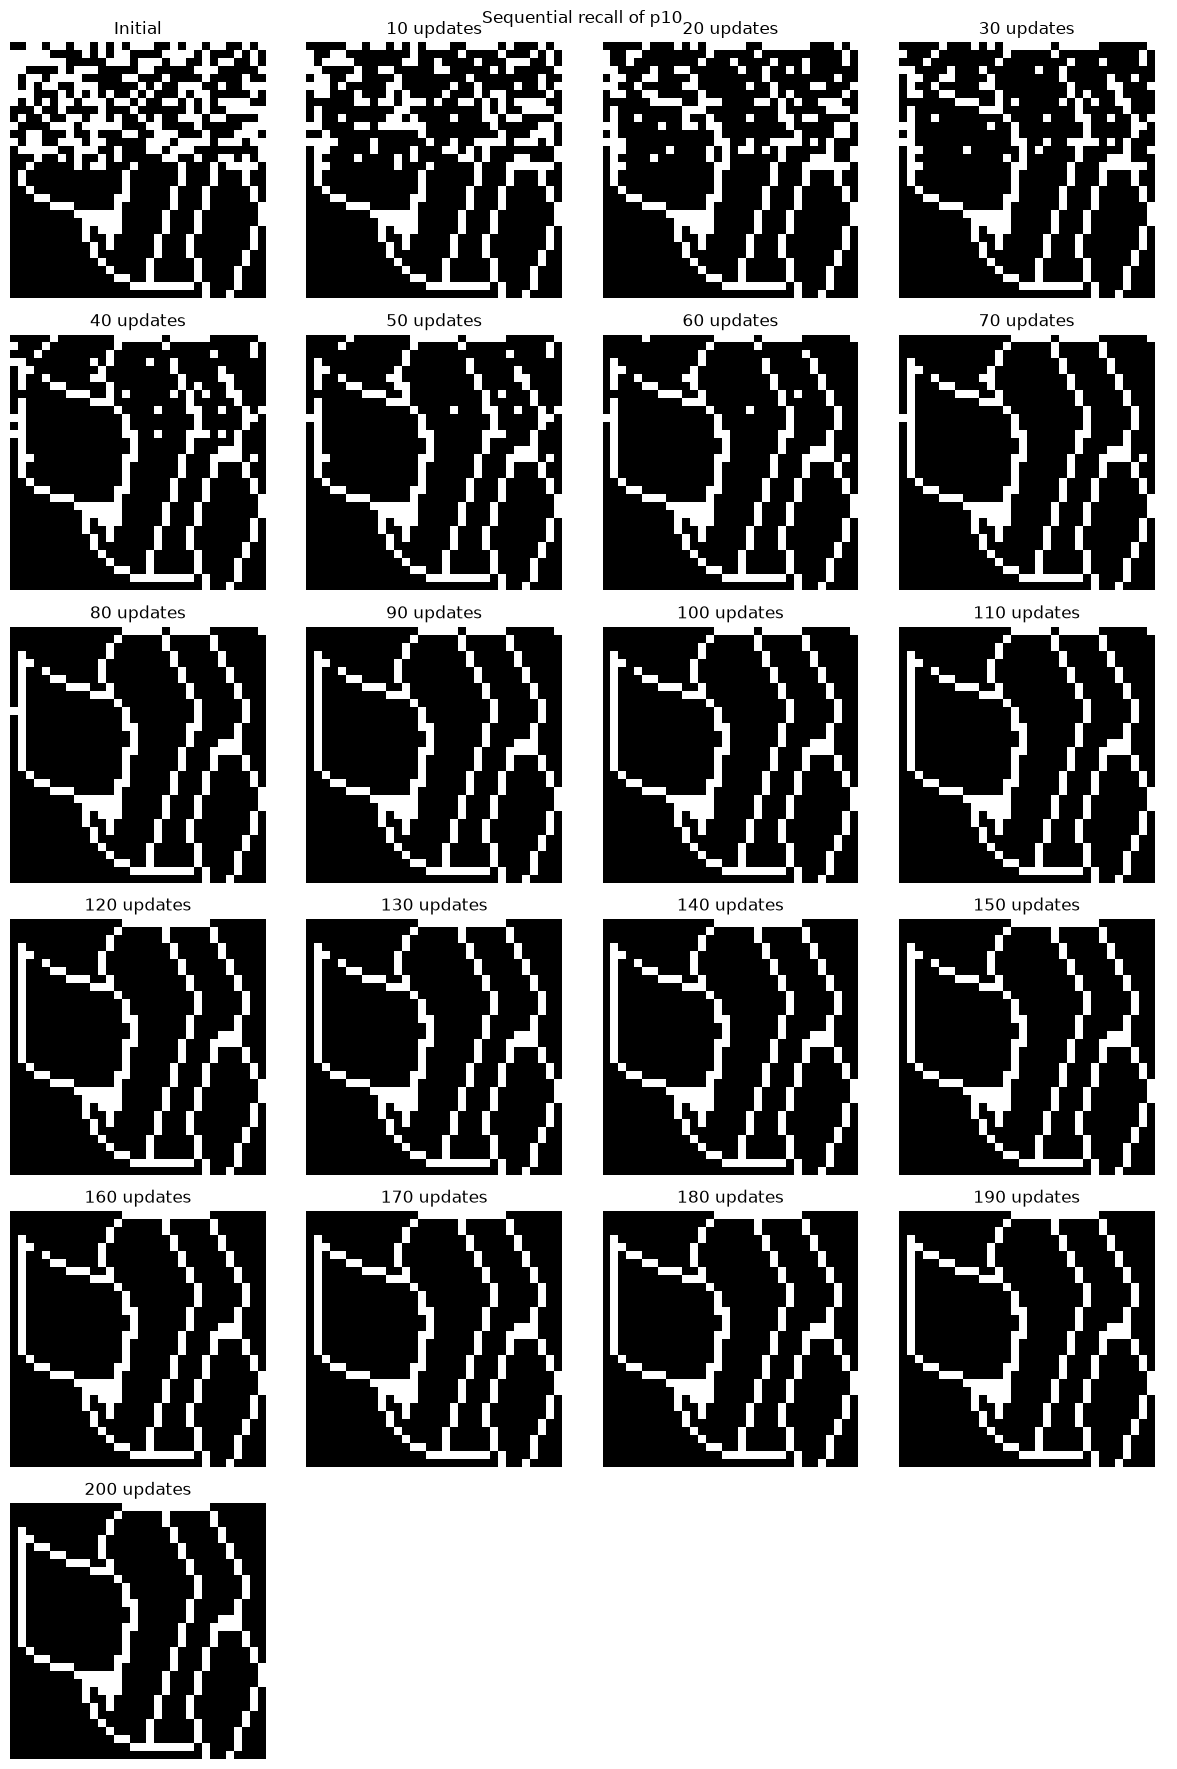

Iteration 500: Energy = -373036.0
Iteration 1000: Energy = -686336.0
Iteration 1500: Energy = -948896.0
Iteration 2000: Energy = -1118864.0
Iteration 2500: Energy = -1279808.0
Iteration 3000: Energy = -1345200.0
Iteration 3500: Energy = -1374700.0
Iteration 4000: Energy = -1408528.0
Iteration 4500: Energy = -1435136.0
Iteration 5000: Energy = -1473836.0
Iteration 5500: Energy = -1473836.0
Iteration 6000: Energy = -1489484.0
Iteration 6500: Energy = -1489484.0
Iteration 7000: Energy = -1489484.0
Iteration 7500: Energy = -1497344.0
Iteration 8000: Energy = -1497344.0
Iteration 8500: Energy = -1497344.0
Iteration 9000: Energy = -1497344.0
Iteration 9500: Energy = -1497344.0
Iteration 10000: Energy = -1497344.0
history length: 21


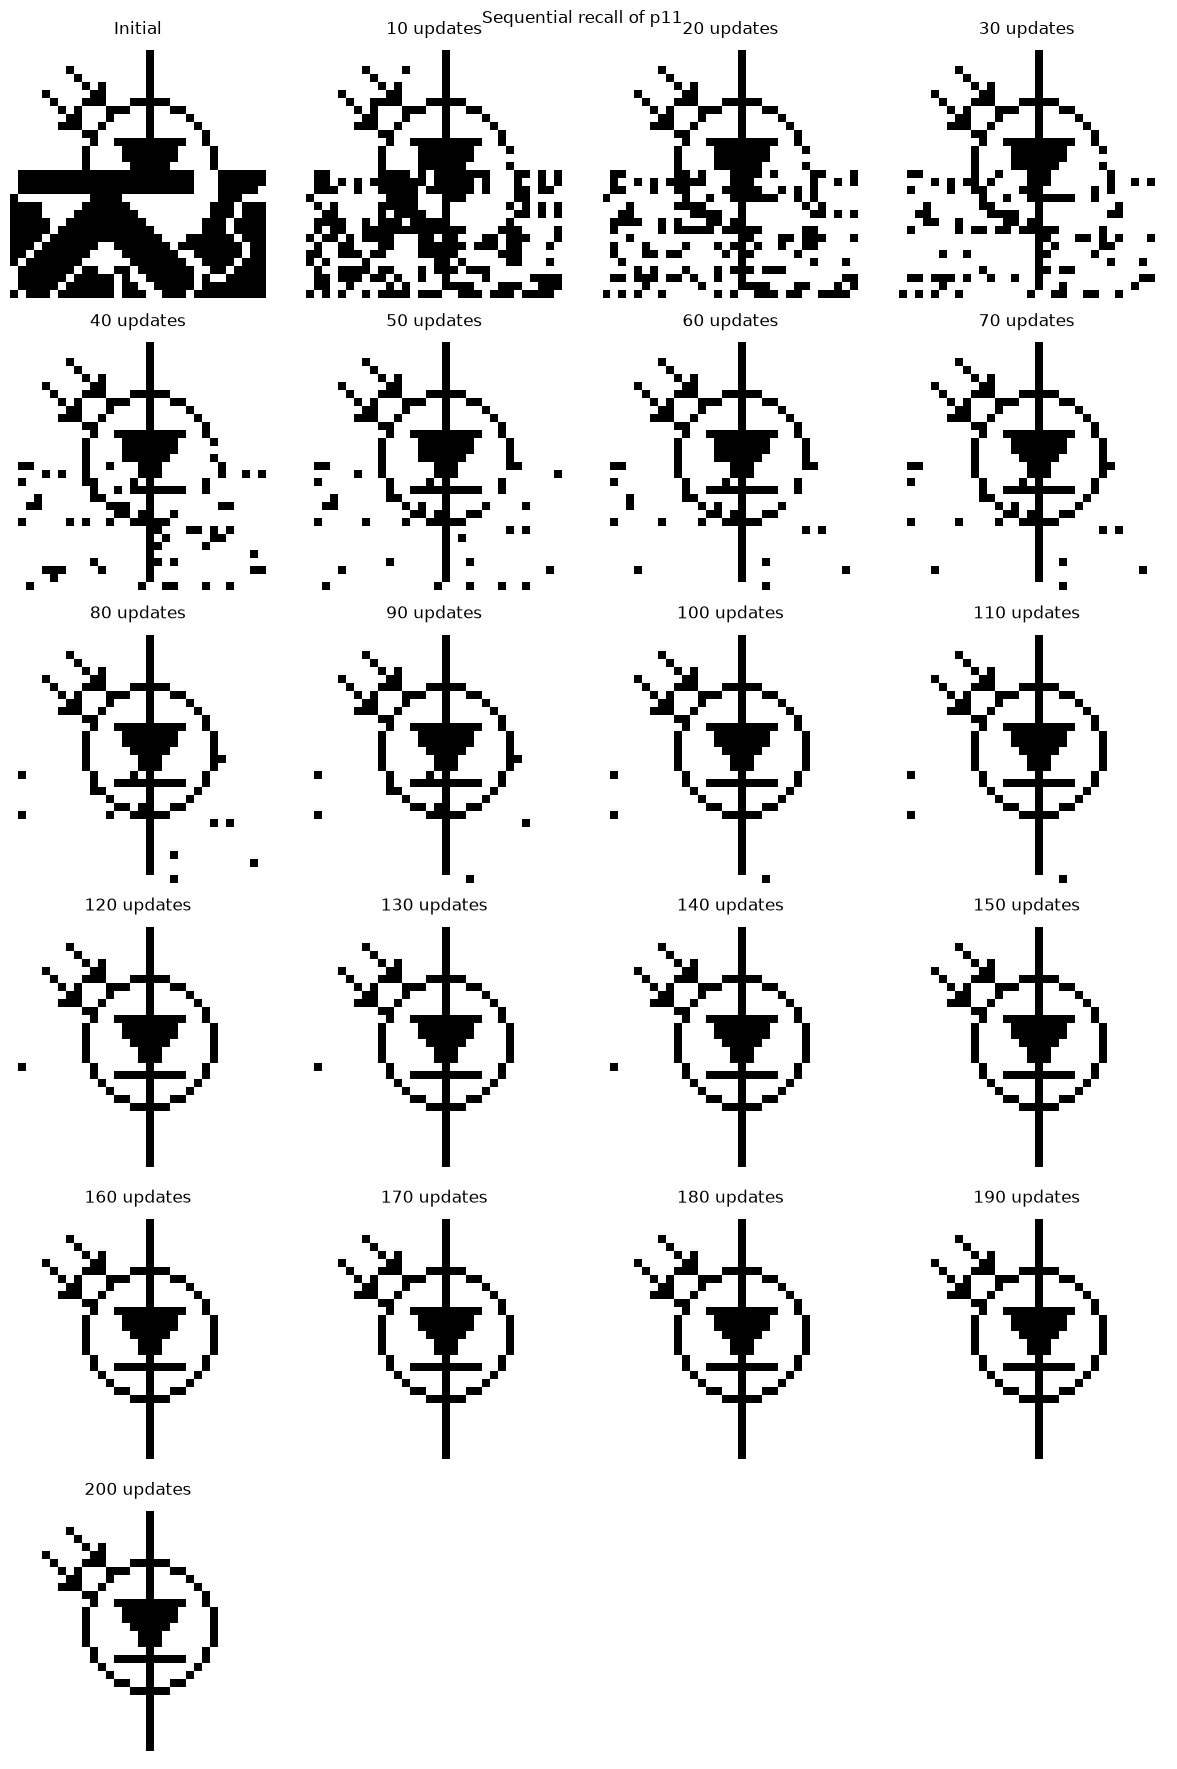

In [10]:
# ------------------------------------------------------------
# 6. Show the sequential dynamics
#    Every 100 iterations
# ------------------------------------------------------------

for name, pattern in test_patterns.items():

    recalled, history = network.recall(
        pattern,
        iterations=10000,
        record_every=500
    )

    # Create enough subplots for every recorded state
    ncols = 4
    nrows = (len(history) + ncols - 1) // ncols

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(12, 3 * nrows)
    )
    axes = np.atleast_1d(axes).flatten()

    print(f"history length: {len(history)}")

    for i, state in enumerate(history):

        axes[i].imshow(
            state.reshape(32, 32),
            cmap="gray"
        )

        if i == 0:
            axes[i].set_title("Initial")
        else:
            axes[i].set_title(f"{i * 10} updates")

        axes[i].axis("off")

    # Hide unused subplots
    for i in range(len(history), len(axes)):
        axes[i].axis("off")

    plt.suptitle(f"Sequential recall of {name}")
    plt.tight_layout()
    plt.show()

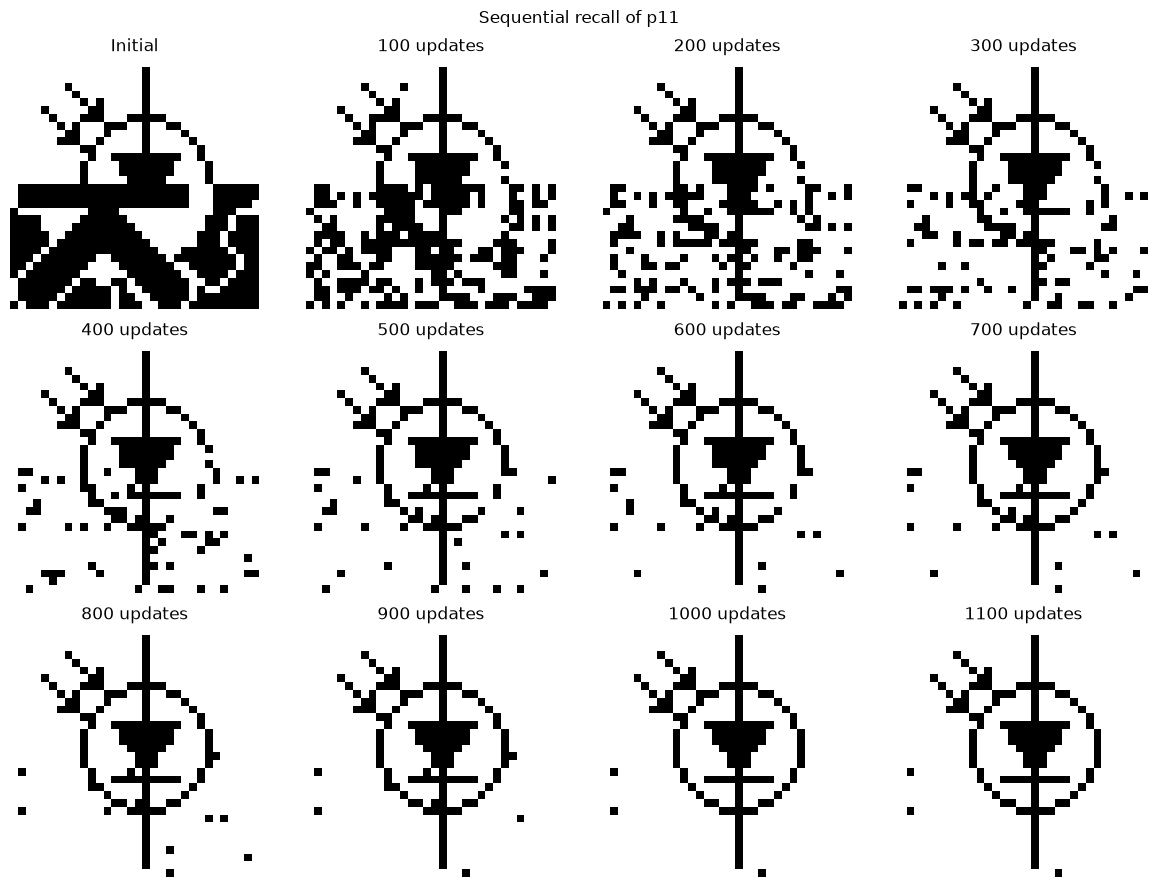

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, state in enumerate(history):

    if i >= len(axes):
        break

    axes[i].imshow(
        state.reshape(32, 32),
        cmap="gray"
    )

    if i == 0:
        axes[i].set_title("Initial")
    else:
        axes[i].set_title(f"{i * 100} updates")

    axes[i].axis("off")

# Hide unused subplot
for i in range(len(history), len(axes)):
    axes[i].axis("off")

plt.suptitle(f"Sequential recall of {name}")
plt.tight_layout()
plt.show()

Energies for the trained network:
 x1:    -68.0
 x2:    -68.0
 x3:    -72.0
x1d:    -40.0
x2d:     -8.0
x3d:    -24.0

Sequential recall from x1d:
final state: [-1 -1  1 -1  1 -1 -1  1]
recalled x1: True
energy never increased: True


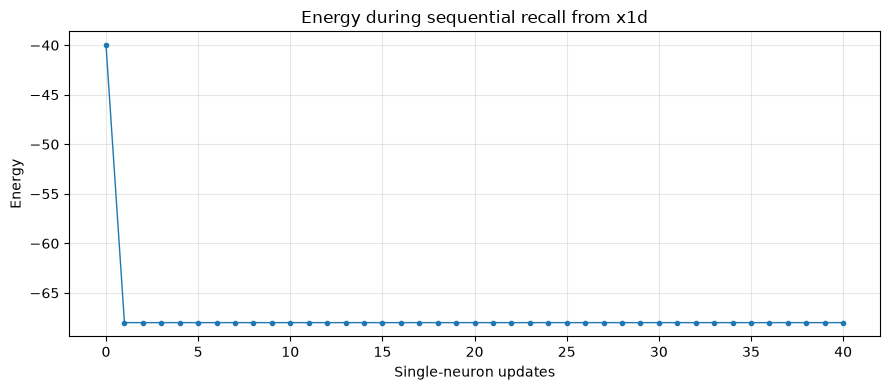


Random-weight convergence test:
nonsymmetric matrix symmetric: False
symmetric matrix symmetric: True
nonsymmetric energy increased: True
symmetric energy never increased: False
nonsymmetric repeated state: (3, 4)
symmetric repeated state: (3, 4)


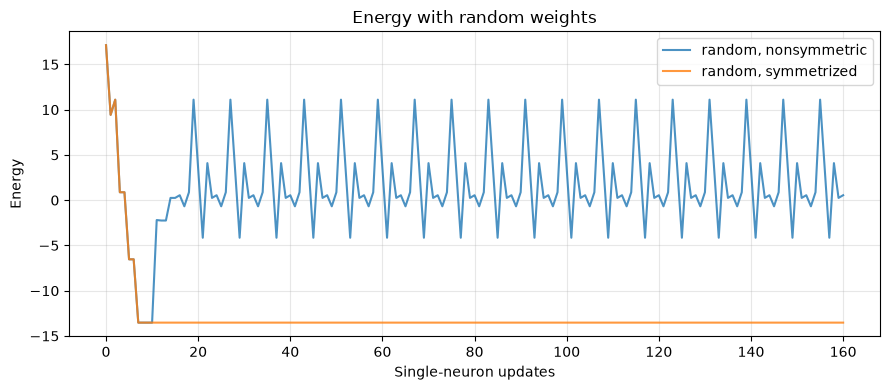

In [12]:
# Section 3.3: energy and convergence
# The assignment defines E(x) = -sum_ij w_ij x_i x_j.
def assignment_energy(weights, state):
    state = np.asarray(state)
    return float(-state @ weights @ state)


def asynchronous_trajectory(weights, initial_state, sweeps=20, order=None):
    """Update one neuron at a time and record energy after every update."""
    state = np.asarray(initial_state, dtype=int).copy()
    n_neurons = len(state)
    order = np.arange(n_neurons) if order is None else np.asarray(order)
    states = [state.copy()]
    energies = [assignment_energy(weights, state)]

    for _ in range(sweeps):
        for neuron in order:
            activation = weights[neuron] @ state
            state[neuron] = 1 if activation >= 0 else -1
            states.append(state.copy())
            energies.append(assignment_energy(weights, state))

    return state, states, np.asarray(energies)


# Energies of the learned attractors and the distorted starting points.
learned_weights = hopfield.W
energy_states = {
    "x1": x1,
    "x2": x2,
    "x3": x3,
    "x1d": x1d,
    "x2d": x2d,
    "x3d": x3d,
}

print("Energies for the trained network:")
for name, state in energy_states.items():
    print(f"{name:>3}: {assignment_energy(learned_weights, state):8.1f}")

# Follow the energy while recalling a distorted pattern asynchronously.
recalled_state, recalled_states, recalled_energies = asynchronous_trajectory(
    learned_weights, x1d, sweeps=5
)
print("\nSequential recall from x1d:")
print(f"final state: {recalled_state}")
print(f"recalled x1: {np.array_equal(recalled_state, x1)}")
print(f"energy never increased: {np.all(np.diff(recalled_energies) <= 1e-12)}")

plt.figure(figsize=(9, 4))
plt.plot(recalled_energies, marker=".", linewidth=1)
plt.xlabel("Single-neuron updates")
plt.ylabel("Energy")
plt.title("Energy during sequential recall from x1d")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Compare an arbitrary random matrix with its symmetric counterpart.
rng = np.random.default_rng(7)
random_weights = rng.normal(size=learned_weights.shape)
symmetric_weights = 0.5 * (random_weights + random_weights.T)
random_state = rng.choice([-1, 1], size=learned_weights.shape[0])

random_final, random_states, random_energies = asynchronous_trajectory(
    random_weights, random_state, sweeps=20
)
symmetric_final, symmetric_states, symmetric_energies = asynchronous_trajectory(
    symmetric_weights, random_state, sweeps=20
)

# A repeated state indicates a cycle for this deterministic update schedule.
def first_repeated_state(states):
    seen = {}
    for step, state in enumerate(states):
        key = tuple(state)
        if key in seen:
            return seen[key], step
        seen[key] = step
    return None

print("\nRandom-weight convergence test:")
print(f"nonsymmetric matrix symmetric: {np.allclose(random_weights, random_weights.T)}")
print(f"symmetric matrix symmetric: {np.allclose(symmetric_weights, symmetric_weights.T)}")
print(f"nonsymmetric energy increased: {np.any(np.diff(random_energies) > 1e-12)}")
print(f"symmetric energy never increased: {np.all(np.diff(symmetric_energies) <= 1e-12)}")
print(f"nonsymmetric repeated state: {first_repeated_state(random_states)}")
print(f"symmetric repeated state: {first_repeated_state(symmetric_states)}")

plt.figure(figsize=(9, 4))
plt.plot(random_energies, label="random, nonsymmetric", alpha=0.8)
plt.plot(symmetric_energies, label="random, symmetrized", alpha=0.8)
plt.xlabel("Single-neuron updates")
plt.ylabel("Energy")
plt.title("Energy with random weights")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
